In [1]:
import pandas as pd
import plotly.express as px

In [2]:

file_path = "AHS_2024 Tables.xlsx"

# Replace with your actual sheet names
sheet_names = [
    "Table1",
    "Table32",
    "Table34",
    "Table 2",
    # "Bank_Account"
]

sheets = pd.read_excel(
    file_path,
    sheet_name=sheet_names,
    header=None
)

print(sheets.keys())



dict_keys(['Table1', 'Table32', 'Table34', 'Table 2'])


C:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: Contents!$1:$69.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")


In [3]:
def extract_province_data(df):
    
    provinces = ["Kigali", "South", "West", "North", "East"]

    extracted = []

    for idx, row in df.iterrows():

        row_text = " ".join(
            str(x) for x in row if pd.notna(x)
        )

        for province in provinces:

            if province in row_text:
                extracted.append(row.tolist())
                break

    return pd.DataFrame(extracted)

In [4]:
bank_df = extract_province_data(
    sheets["Table32"]
)

bank_df.columns = [
    "",
    "Province",
    "HH_Bank_Percentage",
    "HH_Bank_Number",
    "Farmer_Bank_Percentage",
    "Farmer_Bank_Number"
]

print(bank_df)

      Province  HH_Bank_Percentage  HH_Bank_Number  Farmer_Bank_Percentage  \
0 NaN   Kigali               56.87        37.08948                   46.01   
1 NaN    South               63.27       590.49840                   50.20   
2 NaN     West               65.10       454.19110                   45.83   
3 NaN    North               67.49       400.14400                   48.27   
4 NaN     East               58.14       681.65700                   42.16   

   Farmer_Bank_Number  
0            48.62871  
1           747.52590  
2           615.36640  
3           547.59420  
4           870.52320  


In [5]:
farmer_df = extract_province_data(
    sheets["Table 2"]
)

farmer_df.columns = [
    "",
    "",
    "Poor",
    "Non poor",
    "Total"
]

In [6]:
loan_df = extract_province_data(
    sheets["Table34"]
)

loan_df.columns = [
    "",
    "Province",
    "HH_Loan_Percentage",
    "HH_Loan_Number",
    "Farmer_Loan_Percentage",
    "Farmer_Loan_Number"
]

print(loan_df)

      Province  HH_Loan_Percentage  HH_Loan_Number  Farmer_Loan_Percentage  \
0 NaN   Kigali               67.99        37.08948                   33.85   
1 NaN    South               69.97       590.49840                   44.52   
2 NaN     West               80.30       454.19110                   46.61   
3 NaN    North               65.97       400.14400                   35.92   
4 NaN     East               69.08       681.65700                   44.14   

   Farmer_Loan_Number  
0            56.84702  
1           970.87140  
2           780.37270  
3           690.03640  
4          1093.72040  


In [7]:
dashboard_df = (
    bank_df
    .merge(loan_df, on="Province")
)

dashboard_df

,_x,Province,HH_Bank_Percentage,HH_Bank_Number,Farmer_Bank_Percentage,Farmer_Bank_Number,_y,HH_Loan_Percentage,HH_Loan_Number,Farmer_Loan_Percentage,Farmer_Loan_Number
0,NaN,Kigali,56.87,37.08948,46.01,48.62871,NaN,67.99,37.08948,33.85,56.84702
1,NaN,South,63.27,590.49840,50.20,747.52590,NaN,69.97,590.49840,44.52,970.87140
2,NaN,West,65.10,454.19110,45.83,615.36640,NaN,80.30,454.19110,46.61,780.37270
3,NaN,North,67.49,400.14400,48.27,547.59420,NaN,65.97,400.14400,35.92,690.03640
4,NaN,East,58.14,681.65700,42.16,870.52320,NaN,69.08,681.65700,44.14,1093.72040


In [8]:
dashboard_df["Loan_to_Bank_Ratio"] = (
    dashboard_df["HH_Loan_Percentage"] /
    dashboard_df["HH_Bank_Percentage"]
)

dashboard_df["Financial_Inclusion_Gap"] = (
    dashboard_df["HH_Loan_Percentage"] -
    dashboard_df["HH_Bank_Percentage"]
)

In [11]:
dashboard_df.to_csv(
    "dashboard_data.csv",
    index=False
)

print("CSV exported successfully.")

CSV exported successfully.


   _x Province  HH_Bank_Percentage  HH_Bank_Number  Farmer_Bank_Percentage  \
0 NaN   Kigali               56.87        37.08948                   46.01   
1 NaN    South               63.27       590.49840                   50.20   
2 NaN     West               65.10       454.19110                   45.83   
3 NaN    North               67.49       400.14400                   48.27   
4 NaN     East               58.14       681.65700                   42.16   

   Farmer_Bank_Number  _y  HH_Loan_Percentage  HH_Loan_Number  \
0            48.62871 NaN               67.99        37.08948   
1           747.52590 NaN               69.97       590.49840   
2           615.36640 NaN               80.30       454.19110   
3           547.59420 NaN               65.97       400.14400   
4           870.52320 NaN               69.08       681.65700   

   Farmer_Loan_Percentage  Farmer_Loan_Number  Loan_to_Bank_Ratio  \
0                   33.85            56.84702            1.195534   
1 

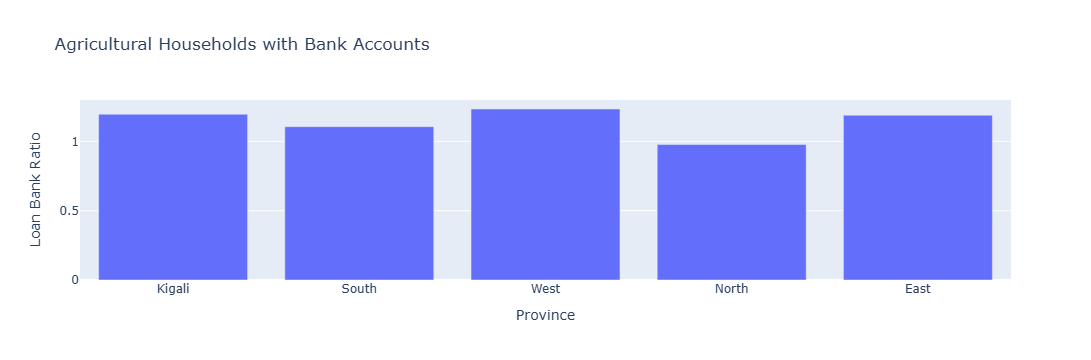

In [9]:
print(dashboard_df)
print(dashboard_df.shape)
fig = px.bar(
    dashboard_df,
    x="Province",
    y="Loan_to_Bank_Ratio",
    title="Agricultural Households with Bank Accounts",
    labels={
        "Loan_to_Bank_Ratio": "Loan Bank Ratio",
        "Province": "Province"
    }
)

fig.show()

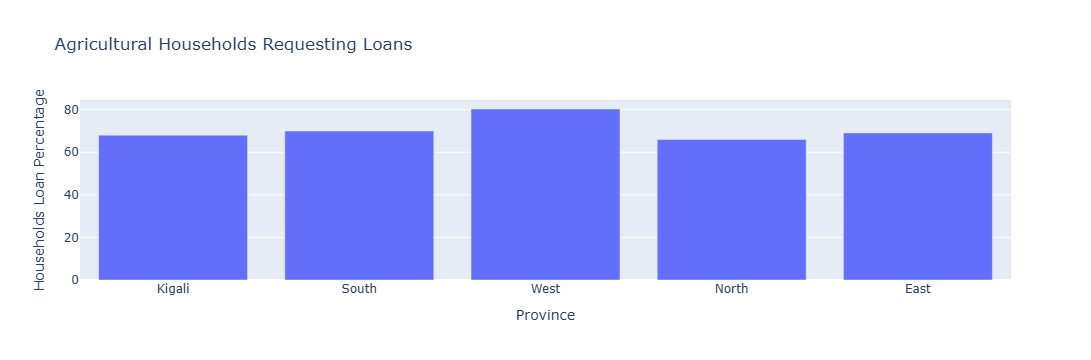

In [10]:
fig = px.bar(
    dashboard_df,
    x="Province",
    y="HH_Loan_Percentage",
    title="Agricultural Households Requesting Loans",
    labels={
        "HH_Loan_Percentage":"Households Loan Percentage",
        "Province": "Province"
    }
)

labels={
        "Loan_to_Bank_Ratio": "Loan Bank Ratio",
        "Province": "Province"
    }
fig.show()